In [1]:
from model import CNNModel 
import torch 

device = "cuda"


d:\Projects\ITMO\EfficientNN\venv\Lib\site-packages\torch\cuda\__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [9]:
validation_imgsz = [
    32,
    64,
    80,
    96,
    128,
    224,
    256,
    384,
    400,
    416,
    512,
    1024,
]

validation_batch = [
    1, 
    2,
    4,
    8,
    16,
    18,
    32,
    64,
    88,
    128,
    130,
    256,
    512,
]

In [3]:
model = CNNModel()
torch.backends.cudnn.benchmark = False        # main results: PyTorch's default heuristics choose the kernel
torch.backends.cudnn.allow_tf32 = False       # so that FP32 means FP32 on Ampere and newer GPUs
torch.backends.cuda.matmul.allow_tf32 = False
model = model.cuda().eval()

for imgsz in validation_imgsz: 
    for batch in validation_batch:
        img = torch.rand(batch, 3, imgsz, imgsz, dtype=torch.float32).to(device)
        try: 
            with torch.no_grad(): 
                model(img) 
            print(f"Succesfull for imgsz: {imgsz} and batch: {batch}")
        except torch.cuda.OutOfMemoryError as e: 
            print(f"OOM with imgsz: {imgsz} and batch: {batch}")

Succesfull for imgsz: 32 and batch: 1
Succesfull for imgsz: 32 and batch: 2
Succesfull for imgsz: 32 and batch: 4
Succesfull for imgsz: 32 and batch: 8
Succesfull for imgsz: 32 and batch: 16
Succesfull for imgsz: 32 and batch: 18
Succesfull for imgsz: 32 and batch: 32
Succesfull for imgsz: 32 and batch: 64
Succesfull for imgsz: 32 and batch: 88
Succesfull for imgsz: 32 and batch: 128
Succesfull for imgsz: 32 and batch: 130
Succesfull for imgsz: 32 and batch: 256
Succesfull for imgsz: 32 and batch: 512
Succesfull for imgsz: 64 and batch: 1
Succesfull for imgsz: 64 and batch: 2
Succesfull for imgsz: 64 and batch: 4
Succesfull for imgsz: 64 and batch: 8
Succesfull for imgsz: 64 and batch: 16
Succesfull for imgsz: 64 and batch: 18
Succesfull for imgsz: 64 and batch: 32
Succesfull for imgsz: 64 and batch: 64
Succesfull for imgsz: 64 and batch: 88
Succesfull for imgsz: 64 and batch: 128
Succesfull for imgsz: 64 and batch: 130
Succesfull for imgsz: 64 and batch: 256
Succesfull for imgsz: 64 a

In [4]:
def flops(I, B):
    return B * (17779 * I**2 + 313600)

def memory(I, B):

    model_memory = 4_174_632

    activations = 4 * B * (33 * I**2 + 868)

    return model_memory + activations

def bytes_moved(I, B):
    return 4 * (
        105 * B * I**2
        + 2148 * B
        + 1_043_652
    )

def latency(I, B, theta):
    F = flops(I, B)
    Q = bytes_moved(I, B)

    t0 = theta["t0"]
    alpha = theta["alpha"]
    beta = theta["beta"]

    return t0 + np.maximum(
        alpha * F,
        beta * Q,
    )

def energy(I, B, theta_energy):
    F = flops(I, B)
    Q = bytes_moved(I, B)

    e0 = theta_energy["e0"]
    e_flop = theta_energy["e_flop"]
    e_byte = theta_energy["e_byte"]

    return (
        e0
        + e_flop * F
        + e_byte * Q
    )

In [5]:
import pandas as pd
import numpy as np
import json
import os
import time
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, lsq_linear


In [6]:
try:
    import pynvml
    pynvml.nvmlInit()
    nvml_handle = pynvml.nvmlDeviceGetHandleByIndex(0)
except Exception:
    nvml_handle = None


def measure_latency(img, repeats=10):
    with torch.inference_mode():
        for _ in range(3):
            model(img)

    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)
    times = []

    with torch.inference_mode():
        for _ in range(repeats):
            start.record()
            model(img)
            end.record()
            torch.cuda.synchronize()
            times.append(start.elapsed_time(end) / 1000)

    return float(np.median(times))


def measure_memory(img):
    torch.cuda.reset_peak_memory_stats()

    with torch.inference_mode():
        output = model(img)

    torch.cuda.synchronize()
    result = torch.cuda.max_memory_allocated()
    del output

    return int(result)


def measure_energy(img, repeats=10):
    if nvml_handle is None:
        return np.nan

    try:
        torch.cuda.synchronize()
        energy_start = pynvml.nvmlDeviceGetTotalEnergyConsumption(nvml_handle)

        with torch.inference_mode():
            for _ in range(repeats):
                model(img)

        torch.cuda.synchronize()
        energy_end = pynvml.nvmlDeviceGetTotalEnergyConsumption(nvml_handle)

        return (energy_end - energy_start) / 1000 / repeats

    except Exception:
        torch.cuda.synchronize()
        power_start = pynvml.nvmlDeviceGetPowerUsage(nvml_handle) / 1000
        time_start = time.perf_counter()

        with torch.inference_mode():
            for _ in range(repeats):
                model(img)

        torch.cuda.synchronize()
        time_end = time.perf_counter()
        power_end = pynvml.nvmlDeviceGetPowerUsage(nvml_handle) / 1000

        return ((power_start + power_end) / 2) * (time_end - time_start) / repeats


In [10]:
df = None
for imgsz in validation_imgsz:
    for batch in validation_batch:
        f = flops(imgsz, batch)
        m = memory(imgsz, batch)
        bm = bytes_moved(imgsz, batch)


        l_real = np.nan
        m_real = np.nan
        e_real = np.nan
        oom = False
        img = None

        try:
            img = torch.rand(
                batch,
                3,
                imgsz,
                imgsz,
                dtype=torch.float32,
                device=device,
            )

            m_real = measure_memory(img)
            l_real = measure_latency(img)
            e_real = measure_energy(img)

            print(f"Successful for imgsz: {imgsz} and batch: {batch}")

        except torch.cuda.OutOfMemoryError:
            oom = True
            print(f"OOM with imgsz: {imgsz} and batch: {batch}")

        finally:
            if img is not None:
                del img
            torch.cuda.empty_cache()

        row = pd.DataFrame({
            "imgsz": [imgsz],
            "batch": [batch],
            "flops": [f],
            "memory_pred_bytes": [m],
            "bytes_moved": [bm],
            "latency_s": [l_real],
            "memory_bytes": [m_real],
            "energy_j": [e_real],
            "oom": [oom],
        })

        if df is None:
            df = row
        else:
            df = pd.concat(
                (df, row),
                axis=0,
                ignore_index=True,
            )

        os.makedirs("results", exist_ok=True)
        df.to_csv("results/measurements_raw.csv", index=False)


Successful for imgsz: 32 and batch: 1
Successful for imgsz: 32 and batch: 2
Successful for imgsz: 32 and batch: 4
Successful for imgsz: 32 and batch: 8
Successful for imgsz: 32 and batch: 16
Successful for imgsz: 32 and batch: 18
Successful for imgsz: 32 and batch: 32
Successful for imgsz: 32 and batch: 64
Successful for imgsz: 32 and batch: 88
Successful for imgsz: 32 and batch: 128
Successful for imgsz: 32 and batch: 130
Successful for imgsz: 32 and batch: 256
Successful for imgsz: 32 and batch: 512
Successful for imgsz: 64 and batch: 1
Successful for imgsz: 64 and batch: 2
Successful for imgsz: 64 and batch: 4
Successful for imgsz: 64 and batch: 8
Successful for imgsz: 64 and batch: 16
Successful for imgsz: 64 and batch: 18
Successful for imgsz: 64 and batch: 32
Successful for imgsz: 64 and batch: 64
Successful for imgsz: 64 and batch: 88
Successful for imgsz: 64 and batch: 128
Successful for imgsz: 64 and batch: 130
Successful for imgsz: 64 and batch: 256
Successful for imgsz: 64 a

In [11]:
calibration_df = df[
    (~df["oom"])
    & (df["latency_s"].notna())
].copy()

F = calibration_df["flops"].to_numpy()
Q = calibration_df["bytes_moved"].to_numpy()
y_latency = calibration_df["latency_s"].to_numpy()


def latency_error(params):
    theta_current = {
        "t0": params[0],
        "alpha": params[1] / 1e9,
        "beta": params[2] / 1e9,
    }

    pred = latency(
        calibration_df["imgsz"].to_numpy(),
        calibration_df["batch"].to_numpy(),
        theta_current,
    )

    return pred - y_latency


x0 = [
    np.min(y_latency) / 2,
    np.median(y_latency / (F / 1e9)),
    np.median(y_latency / (Q / 1e9)),
]

latency_fit = least_squares(
    latency_error,
    x0=x0,
    bounds=(0, np.inf),
)

theta = {
    "t0": float(latency_fit.x[0]),
    "alpha": float(latency_fit.x[1] / 1e9),
    "beta": float(latency_fit.x[2] / 1e9),
}


energy_df = calibration_df[calibration_df["energy_j"].notna()].copy()

F_energy = energy_df["flops"].to_numpy()
Q_energy = energy_df["bytes_moved"].to_numpy()
y_energy = energy_df["energy_j"].to_numpy()

A = np.column_stack((
    np.ones(len(energy_df)),
    F_energy / 1e9,
    Q_energy / 1e9,
))

energy_fit = lsq_linear(
    A,
    y_energy,
    bounds=(0, np.inf),
)

theta_energy = {
    "e0": float(energy_fit.x[0]),
    "e_flop": float(energy_fit.x[1] / 1e9),
    "e_byte": float(energy_fit.x[2] / 1e9),
}

print("theta:", theta)
print("theta_energy:", theta_energy)

with open("results/theta.json", "w") as f:
    json.dump({
        "latency": theta,
        "energy": theta_energy,
    }, f, indent=4)


theta: {'t0': 4.960041254945872e-14, 'alpha': 6.760330254286694e-13, 'beta': 2.433848152194495e-11}
theta_energy: {'e0': 3.093045859483107e-17, 'e_flop': 4.851076741295402e-11, 'e_byte': 3.1221781838038766e-18}


In [12]:
df["latency_pred_s"] = latency(
    df["imgsz"].to_numpy(),
    df["batch"].to_numpy(),
    theta,
)

df["energy_pred_j"] = energy(
    df["imgsz"].to_numpy(),
    df["batch"].to_numpy(),
    theta_energy,
)

total_memory = torch.cuda.get_device_properties(0).total_memory
df["oom_pred"] = df["memory_pred_bytes"] > total_memory

df.to_csv("results/measurements.csv", index=False)

df


,imgsz,batch,flops,memory_pred_bytes,bytes_moved,latency_s,memory_bytes,energy_j,oom,latency_pred_s,energy_pred_j,oom_pred
0,32,1,18519296,4313272,4613280,0.000326,4.019149e+07,0.0000,False,0.000112,0.000898,False
1,32,2,37038592,4451912,5051952,0.000326,4.022835e+07,0.0000,False,0.000123,0.001797,False
2,32,4,74077184,4729192,5929296,0.000307,4.030208e+07,0.0000,False,0.000144,0.003594,False
3,32,8,148154368,5283752,7683984,0.000883,4.044954e+07,0.0000,False,0.000187,0.007187,False
4,32,16,296308736,6392872,11193360,0.000327,4.074445e+07,0.0000,False,0.000272,0.014374,False
...,...,...,...,...,...,...,...,...,...,...,...,...
151,1024,88,1640579274752,12184738984,38760299664,0.262085,6.312411e+09,45.8011,False,1.109086,79.585760,False
152,1024,128,2386297126912,17721359144,56376720144,0.381949,9.164537e+09,68.4885,False,1.613216,115.761105,True
153,1024,130,2423583019520,17998190152,57257541168,0.399716,9.307144e+09,70.6097,False,1.638422,117.569872,True
154,1024,256,4772594253824,35438543656,112749265680,6.944748,1.829134e+10,378.3954,False,3.226431,231.522210,True


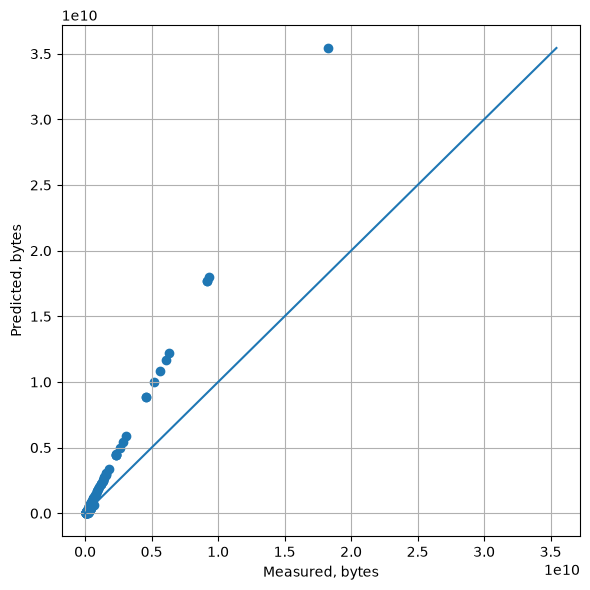

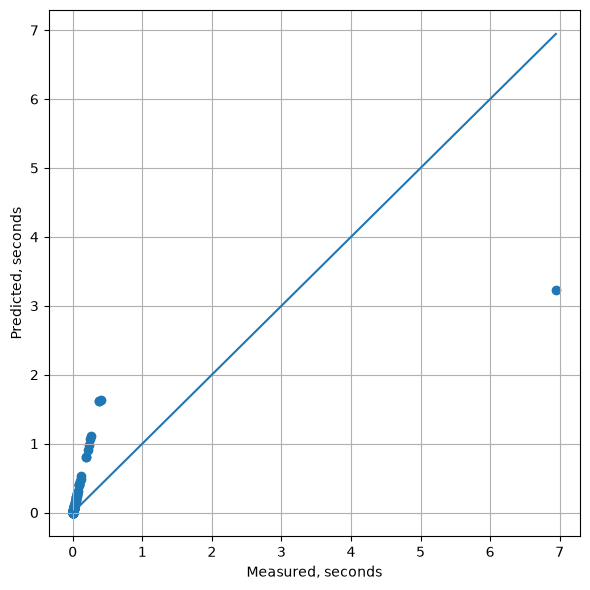

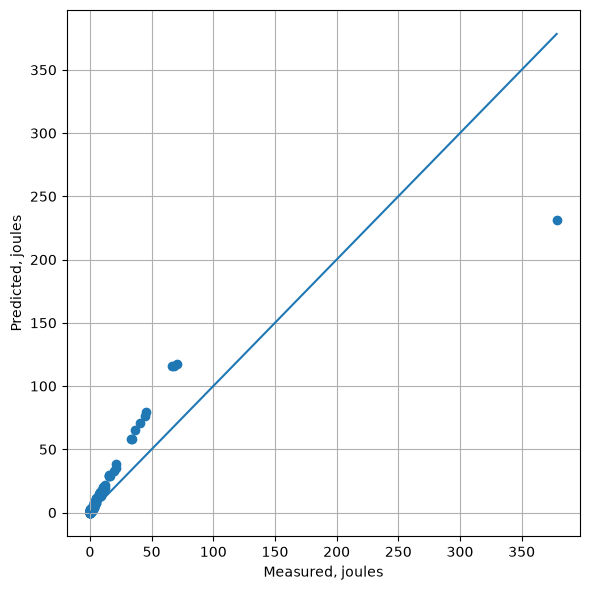

In [13]:
os.makedirs("results/figures", exist_ok=True)


def save_comparison(real_column, pred_column, file_name, units):
    plot_df = df[
        (~df["oom"])
        & (df[real_column].notna())
        & (df[pred_column].notna())
    ]

    real = plot_df[real_column].to_numpy()
    pred = plot_df[pred_column].to_numpy()

    low = min(real.min(), pred.min())
    high = max(real.max(), pred.max())

    plt.figure(figsize=(6, 6))
    plt.scatter(real, pred)
    plt.plot([low, high], [low, high])
    plt.xlabel(f"Measured, {units}")
    plt.ylabel(f"Predicted, {units}")
    plt.grid()
    plt.tight_layout()
    plt.savefig(f"results/figures/{file_name}.png", dpi=150)
    plt.show()


save_comparison(
    "memory_bytes",
    "memory_pred_bytes",
    "memory",
    "bytes",
)

save_comparison(
    "latency_s",
    "latency_pred_s",
    "latency",
    "seconds",
)

save_comparison(
    "energy_j",
    "energy_pred_j",
    "energy",
    "joules",
)
